## Practice: Basic Artificial Neural Networks
Credits: this notebook belongs to [Practical DL](https://docs.google.com/forms/d/e/1FAIpQLScvrVtuwrHSlxWqHnLt1V-_7h2eON_mlRR6MUb3xEe5x9LuoA/viewform?usp=sf_link) course by Yandex School of Data Analysis.

We will start working with neural networks on the practice session. Your homework will be to finish the implementation of the layers.

Our goal is simple, yet an actual implementation may take some time :). We are going to write an Artificial Neural Network (almost) from scratch. The software design was heavily inspired by [PyTorch](http://pytorch.org) which is the main framework of our course 

Speaking about the homework (once again, it will be really similar to this seminar), it requires sending **multiple** files, please do not forget to include all the files when sending to TA. The list of files:
- This notebook
- modules.ipynb with all blocks implemented (except maybe `Conv2d` and `MaxPool2d` layers implementation which are part of 'advanced' version of this homework)

In [1]:
%matplotlib inline
from time import time, sleep
import numpy as np
import matplotlib.pyplot as plt
from IPython import display

# Framework

Implement everything in `modules.ipynb`. Read all the comments thoughtfully to ease the pain. Please try not to change the prototypes.

Do not forget, that each module should return **AND** store `output` and `gradInput`.

The typical assumption is that `module.backward` is always executed after `module.forward`,
so `output` is stored, this would be useful for `SoftMax`. 

### Tech note
Prefer using `np.multiply`, `np.add`, `np.divide`, `np.subtract` instead of `*`,`+`,`/`,`-` for better memory handling.

Example: suppose you allocated a variable 

```
a = np.zeros(...)
```
So, instead of
```
a = b + c  # will be reallocated, GC needed to free
``` 
You can use: 
```
np.add(b,c,out = a) # puts result in `a`
```

In [31]:
# (re-)load layers
%run modules.ipynb

<>:2: SyntaxWarning: invalid escape sequence '\g'
C:\Users\djdjd\AppData\Local\Temp\ipykernel_6676\2367876760.py:2: SyntaxWarning: invalid escape sequence '\g'
  """


# Toy example

Use this example to debug your code, start with logistic regression and then test other layers. You do not need to change anything here. This code is provided for you to test the layers. Also it is easy to use this code in MNIST task.

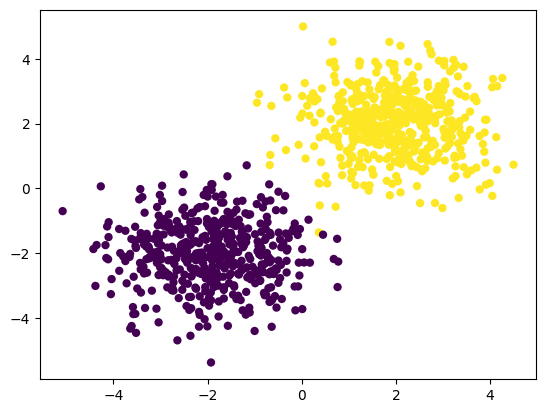

In [3]:
# Generate some data
N = 500

X1 = np.random.randn(N,2) + np.array([2,2])
X2 = np.random.randn(N,2) + np.array([-2,-2])

Y = np.concatenate([np.ones(N),np.zeros(N)])[:,None]
Y = np.hstack([Y, 1-Y])

X = np.vstack([X1,X2])
plt.scatter(X[:,0],X[:,1], c = Y[:,0], edgecolors= 'none')

Define a **logistic regression** for debugging. 

In [4]:
net = Sequential()
net.add(Linear(2, 2))
net.add(LogSoftMax())

criterion = ClassNLLCriterion()

print(net)

# Test something like that then 

# net = Sequential()
# net.add(Linear(2, 4))
# net.add(ReLU())
# net.add(Linear(4, 2))
# net.add(LogSoftMax())

Linear 2 -> 2
LogSoftMax



In [5]:
net = Sequential()
net.add(Linear(2, 4))
net.add(ReLU())
net.add(Linear(4, 2))
net.add(LogSoftMax())

print(net)

Linear 2 -> 4
ReLU
Linear 4 -> 2
LogSoftMax



Start with batch_size = 1000 to make sure every step lowers the loss, then try stochastic version.

In [6]:
# Iptimizer params
optimizer_config = {'learning_rate' : 1e-1, 'momentum': 0.9}
optimizer_state = {}

# Looping params
n_epoch = 20
batch_size = 1000

In [7]:
# batch generator
def get_batches(dataset, batch_size):
    X, Y = dataset
    n_samples = X.shape[0]
        
    # Shuffle at the start of epoch
    indices = np.arange(n_samples)
    np.random.shuffle(indices)
    
    for start in range(0, n_samples, batch_size):
        end = min(start + batch_size, n_samples)
        
        batch_idx = indices[start:end]
    
        yield X[batch_idx], Y[batch_idx]

### Train

Basic training loop. Examine it.

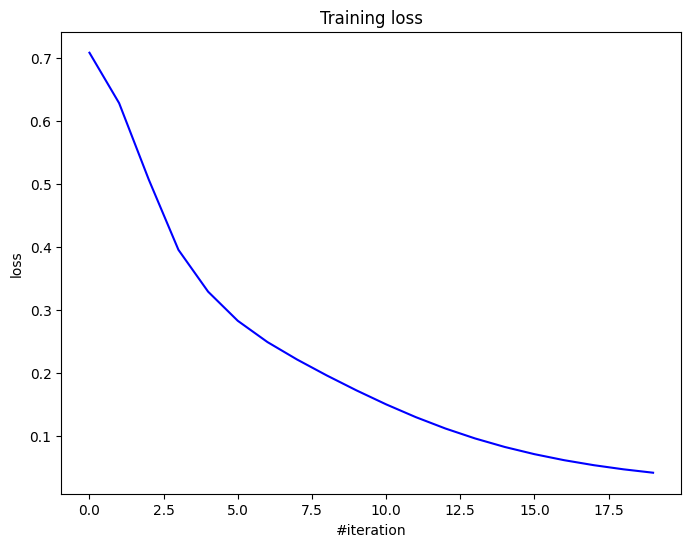

Current loss: 0.042416


In [8]:
loss_history = []

for i in range(n_epoch):
    for x_batch, y_batch in get_batches((X, Y), batch_size):
        
        net.zeroGradParameters()
        
        # Forward
        predictions = net.forward(x_batch)
        loss = criterion.forward(predictions, y_batch)
    
        # Backward
        dp = criterion.backward(predictions, y_batch)
        net.backward(x_batch, dp)
        
        # Update weights
        sgd_momentum(net.getParameters(), 
                     net.getGradParameters(), 
                     optimizer_config,
                     optimizer_state)      
        
        loss_history.append(loss)

    # Visualize
    display.clear_output(wait=True)
    plt.figure(figsize=(8, 6))
        
    plt.title("Training loss")
    plt.xlabel("#iteration")
    plt.ylabel("loss")
    plt.plot(loss_history, 'b')
    plt.show()
    
    print('Current loss: %f' % loss)    

# Digit classification 

We are using old good [MNIST](http://yann.lecun.com/exdb/mnist/) as our dataset. It can be downloaded with the following file.

In [11]:
!wget https://raw.githubusercontent.com/girafe-ai/ml-course/23f_basic/homeworks/hw08_nn_from_scratch/mnist.py -nc

File 'mnist.py' already there; not retrieving.



In [9]:
import mnist
X_train, y_train, X_val, y_val, X_test, y_test = mnist.load_dataset()

One-hot encode the labels first.

In [10]:
import numpy as np

def one_hot(y, num_cls=10):
    return np.eye(num_cls, dtype=np.float32)[y]

In [36]:
y_train_ohe = one_hot(y_train)
y_val_ohe = one_hot(y_val)
y_test_ohe = one_hot(y_test)

- **Compare** `ReLU`, `ELU`, `LeakyReLU`, `SoftPlus` activation functions. 
You would better pick the best optimizer params for each of them, but it is overkill for now. Use an architecture of your choice for the comparison.
- **Try** inserting `BatchNormalization` (folowed by `ChannelwiseScaling`) between `Linear` module and activation functions.
- Plot the losses both from activation functions comparison and `BatchNormalization` comparison on one plot. Please find a scale (log?) when the lines are distinguishable, do not forget about naming the axes, the plot should be goodlooking.
- Plot the losses for two networks: one trained by momentum_sgd, another one trained by Adam. Which one performs better?
- Hint: good logloss for MNIST should be around 0.5. 

In [12]:
def create_mnist_net(activation, use_batchnorm=False):
    net = Sequential()
    net.add(Flatten())

    net.add(Linear(784, 256))
    if use_batchnorm:
        net.add(BatchNormalization(0.9))
        net.add(ChannelwiseScaling(256))
    net.add(activation())

    net.add(Linear(256, 32))
    if use_batchnorm:
        net.add(BatchNormalization(0.9))
        net.add(ChannelwiseScaling(32))
    net.add(activation())

    net.add(Linear(32, 10))
    net.add(LogSoftMax())

    return net

In [18]:
import time

def train_model(
    net,
    optimizer,
    optimizer_config,
    n_epoch=20,
    batch_size=1000
):
    start = time.time()
    criterion = ClassNLLCriterion()
    optimizer_state = {}

    loss_history = []

    for _ in range(n_epoch):
        for x_batch, y_batch in get_batches((X_train, y_train_ohe), batch_size):
            net.zeroGradParameters()

            predictions = net.forward(x_batch)
            loss = criterion.forward(predictions, y_batch)

            dp = criterion.backward(predictions, y_batch)
            net.backward(x_batch, dp)

            optimizer(
                net.getParameters(),
                net.getGradParameters(),
                optimizer_config,
                optimizer_state
            )

            loss_history.append(loss)

    print(f'{time.time() - start:5.1f}s\n')

    return loss_history

In [21]:
activations = [ReLU, ELU, LeakyReLU, SoftPlus]

activation_losses = {}

optimizer_config = {
    'learning_rate': 0.1,
    'momentum': 0.9
}

for activation in activations:
    print(f"Training {activation.__name__}: ", end='')

    net = create_mnist_net(
        activation,
        use_batchnorm=False
    )

    loss_history = train_model(
        net,
        sgd_momentum,
        optimizer_config,
        n_epoch=20,
        batch_size=1000
    )

    activation_losses[activation.__name__] = loss_history

print(f"Training ReLU + BatchNorm: ", end='')

net = create_mnist_net(
    ReLU,
    use_batchnorm=True
)

loss_history = train_model(
    net,
    sgd_momentum,
    optimizer_config,
    n_epoch=20,
    batch_size=1000
)

bn_losses = loss_history

print("Done!")

Training ReLU:  34.9s

Training ELU:  33.0s

Training LeakyReLU:  30.9s

Training SoftPlus:  40.7s

Training ReLU + BatchNorm:  42.4s

Done!


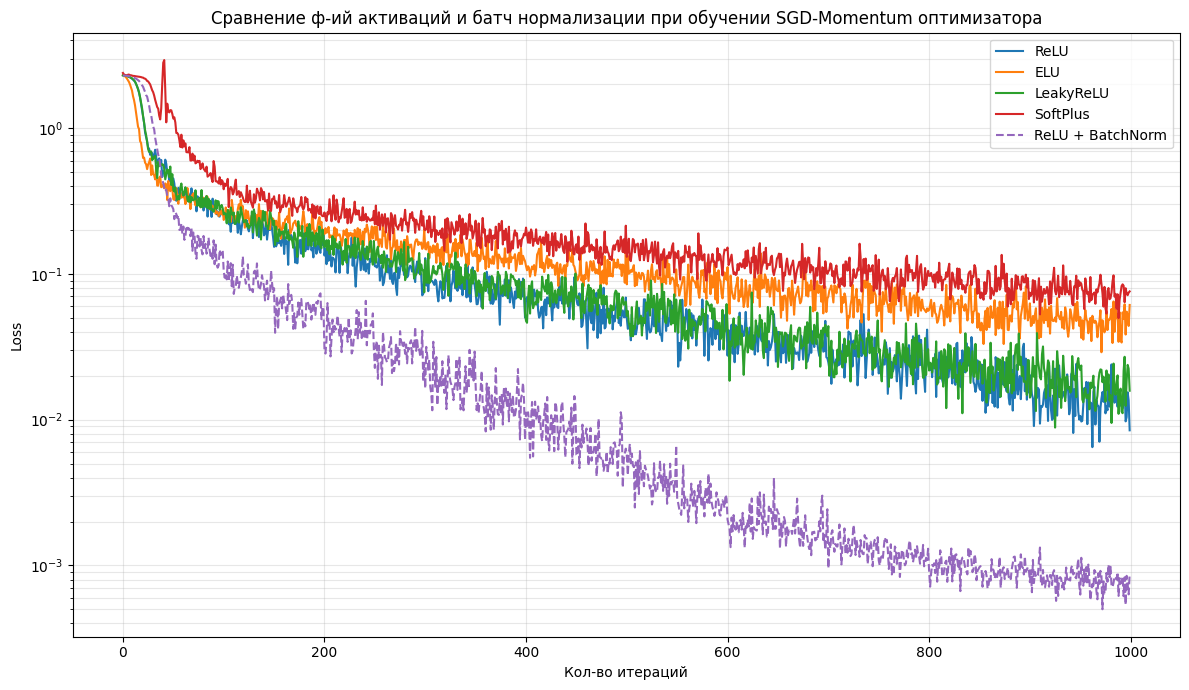

In [22]:
plt.figure(figsize=(12, 7))

for name, losses in activation_losses.items():
    plt.plot(
        losses,
        label=name
    )

plt.plot(
    bn_losses,
    label="ReLU + BatchNorm",
    linestyle="--"
)

plt.yscale("log")

plt.xlabel("Кол-во итераций")
plt.ylabel("Loss")
plt.title("Сравнение ф-ий активаций и батч нормализации при обучении SGD-Momentum оптимизатора")

plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [32]:
activations = [ReLU, ELU, LeakyReLU, SoftPlus]

activation_losses = {}

optimizer_config = {
    'learning_rate': 0.1,
    'beta1': 0.8,
    'beta2': 0.8,
    'epsilon': 1e-8
}

for activation in activations:
    print(f"Training {activation.__name__}: ", end='')

    net = create_mnist_net(
        activation,
        use_batchnorm=False
    )

    loss_history = train_model(
        net,
        adam_optimizer,
        optimizer_config,
        n_epoch=20,
        batch_size=1000
    )

    activation_losses[activation.__name__] = loss_history

print(f"Training ReLU + BatchNorm: ", end='')

net = create_mnist_net(
    ReLU,
    use_batchnorm=True
)

loss_history = train_model(
    net,
    adam_optimizer,
    optimizer_config,
    n_epoch=20,
    batch_size=1000
)

bn_losses = loss_history

print("Done!")

Training ReLU:  30.9s

Training ELU:  39.9s

Training LeakyReLU:  36.5s

Training SoftPlus:  67.0s

Training ReLU + BatchNorm:  54.1s

Done!


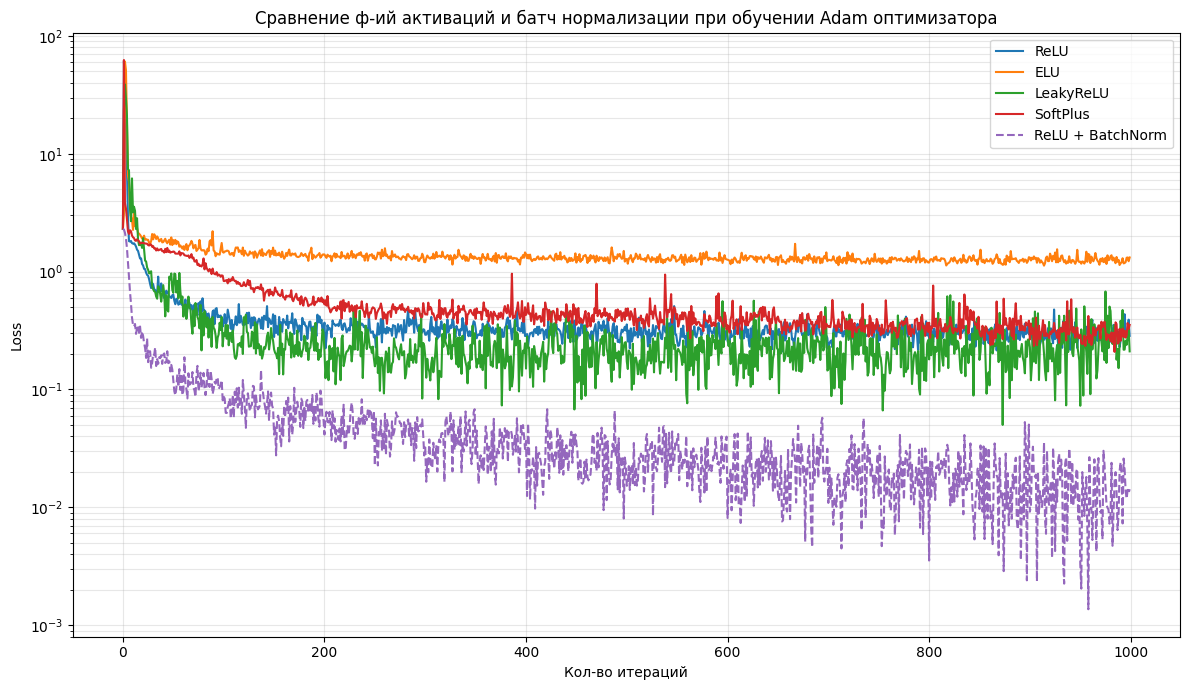

In [33]:
plt.figure(figsize=(12, 7))

for name, losses in activation_losses.items():
    plt.plot(
        losses,
        label=name
    )

plt.plot(
    bn_losses,
    label="ReLU + BatchNorm",
    linestyle="--"
)

plt.yscale("log")

plt.xlabel("Кол-во итераций")
plt.ylabel("Loss")
plt.title("Сравнение ф-ий активаций и батч нормализации при обучении Adam оптимизатора")

plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Write your personal opinion on the activation functions, think about computation times too. Does `BatchNormalization` help?

## Ответ:<br>
Для SGD-Momentum оптимизатора среди функций активации наилучшую сходимость показали ReLU и LeakyReLU, при этом для Adam оптимизатора ReLU, ELU и LeakyReLU достигли близких показателей loss и вышли на плато примерно за 200 итераций. Также добавление батч нормализации позволяет модели с ReLU добиться лучшей сходимости, но вместе с тем требует большего времени на вычисления.

**Finally**, use all your knowledge to build a super cool model on this dataset. Use **dropout** to prevent overfitting, play with **learning rate decay**. You can use **data augmentation** such as rotations, translations to boost your score. Use your knowledge and imagination to train a model. Don't forget to call `training()` and `evaluate()` methods to set desired behaviour of `BatchNormalization` and `Dropout` layers.

In [ ]:
import time

def create_mnist_net(activation, use_batchnorm=False, dropout=0.):
    net = Sequential()
    net.add(Flatten())

    net.add(Linear(784, 512))
    if use_batchnorm:
        net.add(BatchNormalization(0.9))
        net.add(ChannelwiseScaling(512))
    net.add(activation())
    net.add(Dropout(dropout))

    net.add(Linear(512, 256))
    if use_batchnorm:
        net.add(BatchNormalization(0.9))
        net.add(ChannelwiseScaling(256))
    net.add(activation())
    net.add(Dropout(dropout))

    net.add(Linear(256, 10))
    net.add(LogSoftMax())

    return net


def evaluate_model(net, X, y_ohe):
    net.evaluate()
    predictions = net.forward(X)
    net.train()
    loss = ClassNLLCriterion().forward(predictions, y_ohe)
    accuracy = (predictions.argmax(axis=1) == y_ohe.argmax(axis=1)).mean()
    return loss, accuracy


def train_model(
    net,
    optimizer,
    optimizer_config,
    n_epoch=20,
    batch_size=1000,
    lr_decay=1.0,
):
    start = time.time()
    criterion = ClassNLLCriterion()
    optimizer_state = {}

    loss_history = []
    val_history = []

    net.train()
    for epoch in range(n_epoch):
        for x_batch, y_batch in get_batches((X_train, y_train_ohe), batch_size):
            net.zeroGradParameters()

            predictions = net.forward(x_batch)
            loss = criterion.forward(predictions, y_batch)

            dp = criterion.backward(predictions, y_batch)
            net.backward(x_batch, dp)

            optimizer(
                net.getParameters(),
                net.getGradParameters(),
                optimizer_config,
                optimizer_state
            )

            loss_history.append(loss)

        optimizer_config['learning_rate'] *= lr_decay

        val_loss, val_acc = evaluate_model(net, X_val, y_val_ohe)
        val_history.append((val_loss, val_acc))
        print(f'epoch {epoch + 1:2d} | train {np.mean(loss_history[-50:]):.4f} | val {val_loss:.4f} | acc {val_acc:.4f} | {time.time() - start:5.1f}s')

    print(f'{time.time() - start:5.1f}s\n')

    return loss_history, val_history

In [ ]:
np.random.seed(42)
net = create_mnist_net(ReLU, use_batchnorm=True, dropout=0.2)
optimizer_config = {'learning_rate': 2e-3, 'beta1': 0.9, 'beta2': 0.999, 'epsilon': 1e-8}

loss_history, val_history = train_model(
    net,
    adam_optimizer,
    optimizer_config,
    n_epoch=30,
    batch_size=256,
    lr_decay=0.9,
)

epoch  1 | train 0.1461 | val 0.1140 | acc 0.9674 |   9.4s
epoch  2 | train 0.0897 | val 0.0820 | acc 0.9749 |  17.7s
epoch  3 | train 0.0603 | val 0.0690 | acc 0.9798 |  29.6s
epoch  4 | train 0.0445 | val 0.0647 | acc 0.9811 |  45.9s
epoch  5 | train 0.0324 | val 0.0644 | acc 0.9811 |  56.4s
epoch  6 | train 0.0271 | val 0.0621 | acc 0.9825 |  65.0s
epoch  7 | train 0.0210 | val 0.0633 | acc 0.9830 |  74.4s
epoch  8 | train 0.0160 | val 0.0638 | acc 0.9844 |  83.8s
epoch  9 | train 0.0143 | val 0.0643 | acc 0.9830 |  93.8s
epoch 10 | train 0.0099 | val 0.0630 | acc 0.9838 | 105.1s
epoch 11 | train 0.0081 | val 0.0620 | acc 0.9846 | 114.8s
epoch 12 | train 0.0065 | val 0.0633 | acc 0.9852 | 124.7s
epoch 13 | train 0.0076 | val 0.0634 | acc 0.9841 | 134.7s
epoch 14 | train 0.0071 | val 0.0659 | acc 0.9837 | 146.1s
epoch 15 | train 0.0054 | val 0.0654 | acc 0.9838 | 163.9s
epoch 16 | train 0.0041 | val 0.0646 | acc 0.9846 | 177.3s
epoch 17 | train 0.0037 | val 0.0649 | acc 0.9849 | 190.

Print here your accuracy on test set. It should be around 90%.

In [40]:
test_loss, test_acc = evaluate_model(net, X_test, y_test_ohe)
print(f'test loss {test_loss:.4f}, test acc {test_acc:.4f}')

test loss 0.0618, test acc 0.9865


### Comparing with PyTorch implementation
The last (and maybe the easiest step after compared to the previous tasks: build a network with the same architecture as above now with PyTorch.

You can refer to the `week0_09` or `Lab3_part2` notebooks for hints.

__Good Luck!__

In [41]:
import time
import torch
import torch.nn as nn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def create_mnist_net_torch(activation, use_batchnorm=False, dropout=0.):
    layers = [nn.Flatten()]

    layers.append(nn.Linear(784, 512))
    if use_batchnorm:
        layers.append(nn.BatchNorm1d(512, eps=1e-3, momentum=0.1))
    layers.append(activation())
    layers.append(nn.Dropout(dropout))

    layers.append(nn.Linear(512, 256))
    if use_batchnorm:
        layers.append(nn.BatchNorm1d(256, eps=1e-3, momentum=0.1))
    layers.append(activation())
    layers.append(nn.Dropout(dropout))

    layers.append(nn.Linear(256, 10))
    layers.append(nn.LogSoftmax(dim=1))

    return nn.Sequential(*layers)


def evaluate_model_torch(net, X, y):
    net.eval()
    with torch.no_grad():
        predictions = net(torch.from_numpy(X).float().to(device))
        y = torch.from_numpy(y).long().to(device)
        loss = nn.NLLLoss()(predictions, y).item()
        accuracy = (predictions.argmax(dim=1) == y).float().mean().item()
    net.train()
    return loss, accuracy


def train_model_torch(
    net,
    n_epoch=20,
    batch_size=1000,
    learning_rate=1e-3,
    lr_decay=1.0,
):
    start = time.time()
    criterion = nn.NLLLoss()
    optimizer = torch.optim.Adam(net.parameters(), lr=learning_rate, betas=(0.9, 0.999), eps=1e-8)
    scheduler = torch.optim.lr_scheduler.ExponentialLR(optimizer, gamma=lr_decay)

    loss_history = []
    val_history = []

    net.train()
    for epoch in range(n_epoch):
        indices = np.random.permutation(len(X_train))
        for start_idx in range(0, len(indices), batch_size):
            batch_idx = indices[start_idx:start_idx + batch_size]
            x_batch, y_batch = X_train[batch_idx], y_train[batch_idx]

            x_batch = torch.from_numpy(x_batch).float().to(device)
            y_batch = torch.from_numpy(y_batch).long().to(device)

            optimizer.zero_grad()
            loss = criterion(net(x_batch), y_batch)
            loss.backward()
            optimizer.step()

            loss_history.append(loss.item())

        scheduler.step()

        val_loss, val_acc = evaluate_model_torch(net, X_val, y_val)
        val_history.append((val_loss, val_acc))
        print(f'epoch {epoch + 1:2d} | train {np.mean(loss_history[-50:]):.4f} | val {val_loss:.4f} | acc {val_acc:.4f} | {time.time() - start:5.1f}s')

    print(f'{time.time() - start:5.1f}s\n')

    return loss_history, val_history

In [43]:
np.random.seed(42)
torch.manual_seed(42)
net = create_mnist_net_torch(nn.ReLU, use_batchnorm=True, dropout=0.2).to(device)

loss_history, val_history = train_model_torch(
    net,
    n_epoch=30,
    batch_size=256,
    learning_rate=2e-3,
    lr_decay=0.9
)

C:\Users\djdjd\AppData\Local\Temp\ipykernel_6676\241567144.py:32: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  y = torch.from_numpy(y).long().to(device)


epoch  1 | train 0.1464 | val 0.1079 | acc 0.9680 |   5.1s
epoch  2 | train 0.0906 | val 0.0780 | acc 0.9763 |   8.2s
epoch  3 | train 0.0682 | val 0.0772 | acc 0.9770 |  11.2s
epoch  4 | train 0.0511 | val 0.0659 | acc 0.9804 |  14.1s
epoch  5 | train 0.0454 | val 0.0686 | acc 0.9804 |  16.7s
epoch  6 | train 0.0355 | val 0.0585 | acc 0.9825 |  19.1s
epoch  7 | train 0.0221 | val 0.0651 | acc 0.9817 |  21.4s
epoch  8 | train 0.0236 | val 0.0620 | acc 0.9816 |  23.9s
epoch  9 | train 0.0156 | val 0.0643 | acc 0.9820 |  26.1s
epoch 10 | train 0.0127 | val 0.0633 | acc 0.9835 |  28.6s
epoch 11 | train 0.0124 | val 0.0604 | acc 0.9839 |  31.1s
epoch 12 | train 0.0108 | val 0.0638 | acc 0.9847 |  33.3s
epoch 13 | train 0.0088 | val 0.0632 | acc 0.9849 |  35.6s
epoch 14 | train 0.0076 | val 0.0625 | acc 0.9844 |  38.0s
epoch 15 | train 0.0061 | val 0.0630 | acc 0.9846 |  40.5s
epoch 16 | train 0.0061 | val 0.0641 | acc 0.9836 |  42.9s
epoch 17 | train 0.0056 | val 0.0645 | acc 0.9847 |  45.

In [44]:
test_loss, test_acc = evaluate_model_torch(net, X_test, y_test)
print(f'test loss {test_loss:.4f}, test acc {test_acc:.4f}')

test loss 0.0567, test acc 0.9864
